In [1]:
import matplotlib.pyplot as plt
import numpy as np
from taia1dvfd.analysis import LotusData, compute_forecast_score_uv, get_model_variable, score_summary

In [2]:
OUTPUT_FOLDER = "/home/mnex/Desktop/1DV_FD/experiments/2_Lotus_stationary/output"

NENS = 1000
T_START_DAYS = 10   # spin-up excluded from the profile average

CLOSURES = [
    ("k-kl",      r"$k$-$kl$",          "C0"),
    ("k-epsilon", r"$k$-$\varepsilon$", "C1"),
    ("k-omega",   r"$k$-$\omega$",      "C2"),
    ("gen",       r"GLS gen",           "C3"),
    ("tke",       r"TKE",               "C4"),
    ("kpp",       r"KPP",               "C5"),
]
BANDS = {name for name, *_ in CLOSURES}   # closures that get a ±1σ band

In [3]:
obs = LotusData()
ue_obs = obs.u + 1.j * obs.v

def load_exp(exp_name: str, n_ens: int):
    """Read the file once; return what both diagnostics need."""
    z, t, ue_m, ue_v = get_model_variable(
        f"{OUTPUT_FOLDER}/{exp_name}_ne{n_ens}.nc", "ue", cplx=True)

    idx_t = t / 86400 >= T_START_DAYS
    profile = (z, ue_m[idx_t].mean(axis=0), ue_v[idx_t].mean(axis=0))
    score = compute_forecast_score_uv(ue_m, ue_v, z, t, n_ens, ue_obs, obs.z, obs.n)
    return profile, score


def plot_profile_uv(axes, profile, label=None, color=None, band_alpha=0.10):
    z, uem, uev = profile
    for a, m, s in ((axes[0], uem.real, np.sqrt(uev.real)),
                    (axes[1], uem.imag, np.sqrt(uev.imag))):
        a.plot(m, z, color=color, lw=1.4, label=label, zorder=3)
        if band_alpha:
            a.fill_betweenx(z, m - s, m + s, color=color,
                            alpha=band_alpha, lw=0, zorder=1)


data = {name: load_exp(name, NENS) for name, *_ in CLOSURES}

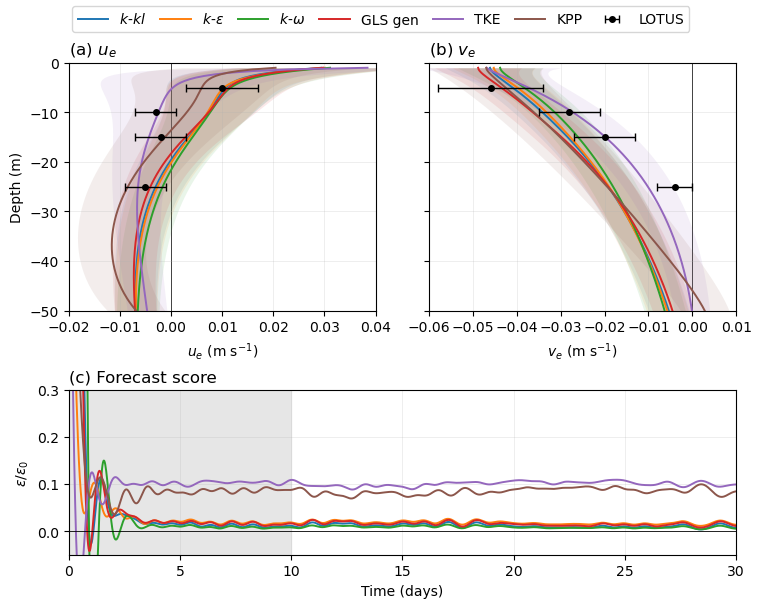

In [4]:
fig, ax = plt.subplot_mosaic([["a", "b"],["c", "c"]], figsize=(7.5, 6), height_ratios=[1.5, 1], layout="constrained")
ax["b"].sharey(ax["a"])
ax["b"].tick_params(labelleft=False)

# (a), (b): time-mean profiles
for name, label, color in CLOSURES:
    plot_profile_uv((ax["a"], ax["b"]), data[name][0], label=label, color=color,
                    band_alpha=0.10 if name in BANDS else 0)

obs_kw = dict(fmt="o", color="k", ms=4, capsize=3, elinewidth=1,
              zorder=5, label="LOTUS")
ax["a"].errorbar(obs.DWC_mean,  obs.z, xerr=obs.DWC_std, **obs_kw)   # u = downwind
ax["b"].errorbar(-obs.CWC_mean, obs.z, xerr=obs.CWC_std, **obs_kw)   # v = -crosswind

for key, comp in (("a", "u"), ("b", "v")):
    ax[key].axvline(0, color="k", lw=0.6, zorder=0)
    ax[key].set_xlabel(rf"${comp}_e$ (m s$^{{-1}}$)")
    ax[key].set_title(rf"({key}) ${comp}_e$", loc="left")
    ax[key].grid(alpha=0.3, lw=0.5)

ax["a"].set_ylim(-50, 0)
ax["a"].set_ylabel("Depth (m)")

ax["a"].set_xlim(-0.02, 0.04)
ax["b"].set_xlim(-0.06, 0.01)

# (c): forecast score
for name, label, color in CLOSURES:
    t, s = data[name][1]
    ax["c"].plot(t, s, color=color, lw=1.4)

ax["c"].axvspan(t[0], T_START_DAYS, color="0.9", zorder=0)   # spin-up, excluded from (a)-(b)
ax["c"].axhline(0, color="k", lw=0.6)
ax["c"].set_xlim(t[0], t[-1])
ax["c"].set_ylim(-0.05, 0.3)
ax["c"].set_xlabel("Time (days)")
ax["c"].set_ylabel(r"$\varepsilon / \varepsilon_0$")
ax["c"].set_title("(c) Forecast score", loc="left")
ax["c"].grid(alpha=0.3, lw=0.5)

# one legend for all panels
handles, labels = ax["a"].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=7, handlelength=2.2, columnspacing=1.0)

In [5]:
def eps_uv(exp_name: str, n_ens: int, **kw):
    z, t, ue_m, ue_v = get_model_variable(f"{OUTPUT_FOLDER}/{exp_name}_ne{n_ens}.nc", "ue", cplx=True)
    return compute_forecast_score_uv(ue_m, ue_v, z, t, n_ens, ue_obs, obs.z, obs.n, **kw)

print(f"{'closure':10s} {'MSE':>7s} {'VAR':>7s} {'VAR/MSE':>8s} {'signed':>8s} {'eps/eps0':>9s}   (MSE, VAR in 1e-5 m2/s2)")
for name, label, _ in CLOSURES:
    s = score_summary(*eps_uv(name, NENS, return_terms=True))
    print(f"{name:10s} {s['MSE']*1e5:7.2f} {s['VAR']*1e5:7.2f} {s['VAR/MSE']:8.2f} "
          f"{s['signed']:8.3f} {s['eps_mean']:9.3f}")

closure        MSE     VAR  VAR/MSE   signed  eps/eps0   (MSE, VAR in 1e-5 m2/s2)
k-kl          6.31    5.78     0.92    0.011     0.011
k-epsilon     6.15    5.36     0.87    0.018     0.018
k-omega       5.88    5.31     0.90    0.008     0.008
gen           6.70    5.99     0.89    0.015     0.015
tke           2.67    7.00     2.62   -0.100     0.100
kpp           6.05    9.84     1.63   -0.085     0.085
